In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

In this lab we will assume that we know the form of the signal-free background distribution (determining a distribution from data will be next week's lab). In each of our three examples, your task will be to state the statistical question, convert it to math, then perform the associated analyses.

## Question 1
In our first example we are looking at the temperature reading (meta-data) associated with an experiment. For the experiment to work reliably, the temperature should be at around 12 Kelvin, and if we look at the data it is mostly consistent with 12 Kelvin to within the 0.4 degree precision of the thermometry and the thermal control system (standard deviation). However, there are times when the thermal control system misbehaved and the temperature was not near 12 K, and in addition there are various glitches in the thermometry that give anomalously high and low readings (the reading does not match the real temperature). We definitely want to identify and throw out all the data when the thermal control system was not working (and the temperature was truly off from nominal). While it is possible to have an error in the thermometry such that the true temperature was fine, and we just had a wonky reading, in an abundance of caution we want to throw those values out too.

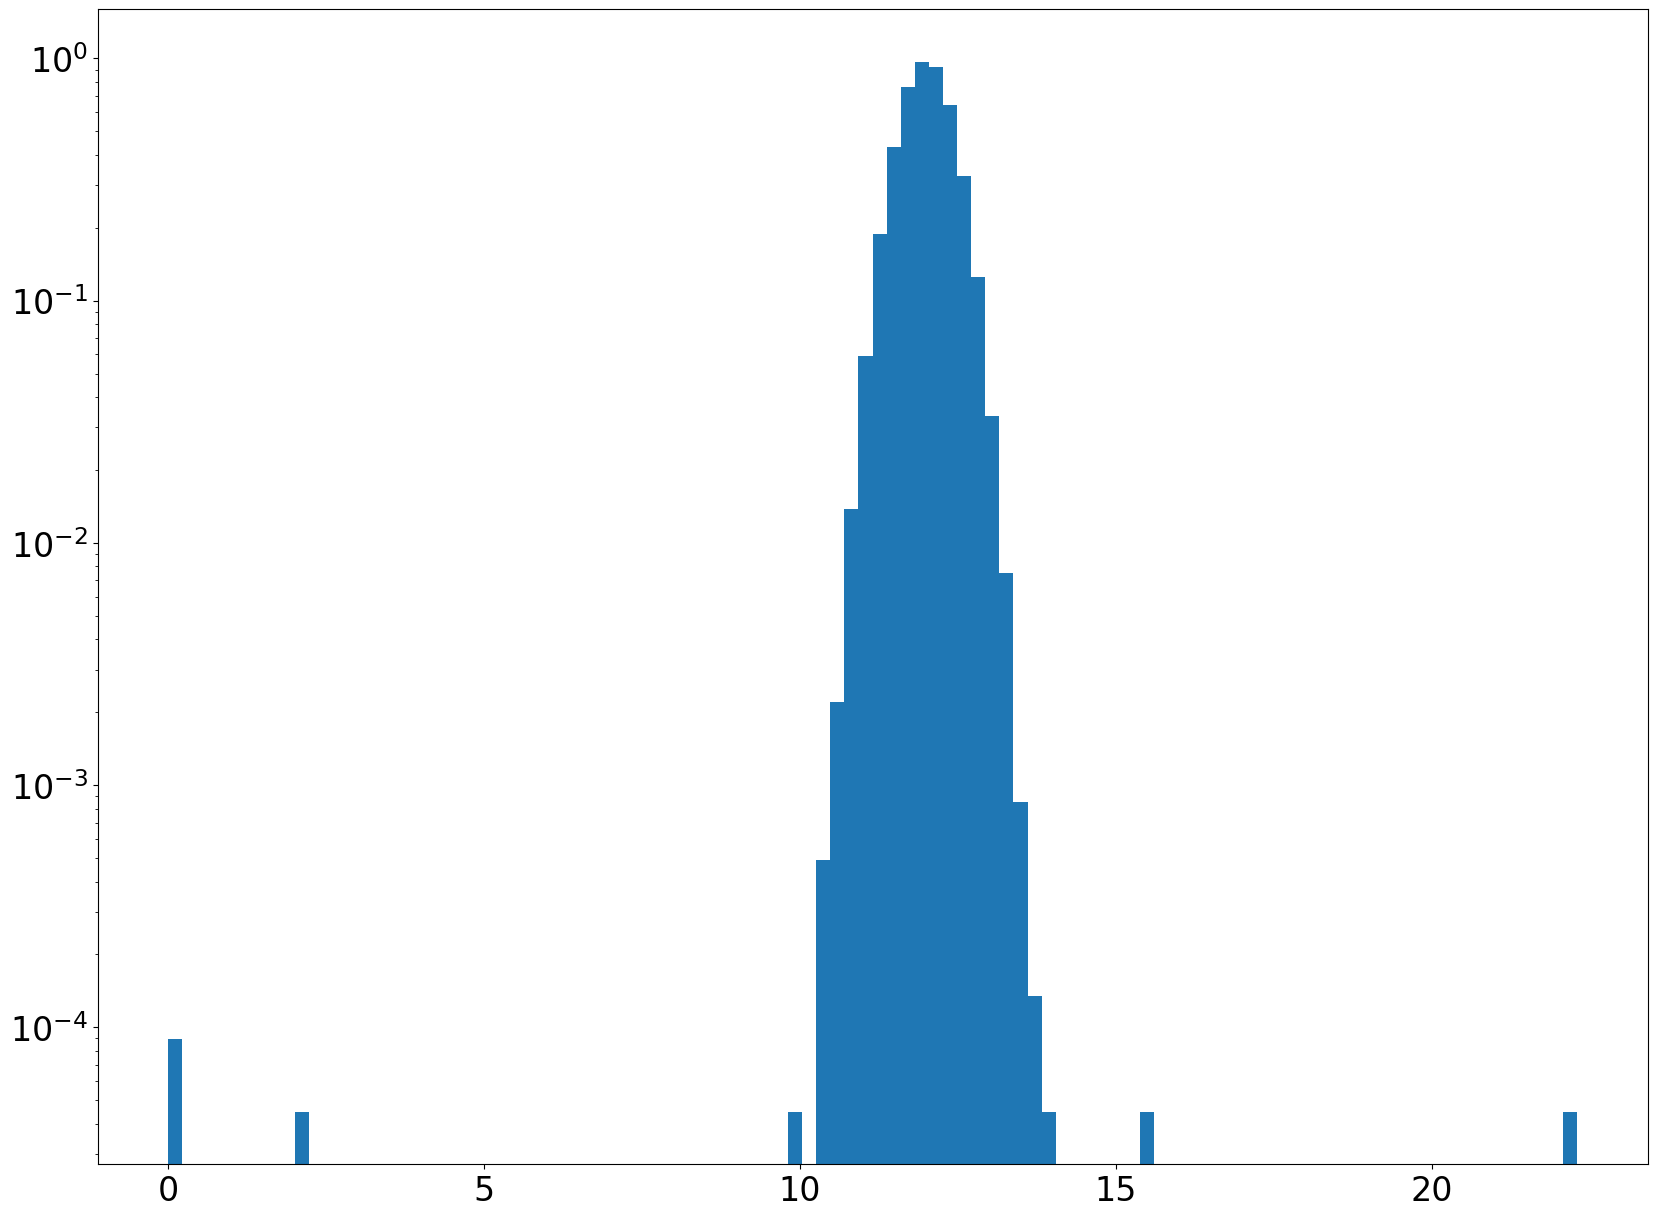

In [2]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

### Part (A)
So our goal is to identify bad data and throw it out.

#### Part (i)
Start by exploring the data you have created with appropriate plots

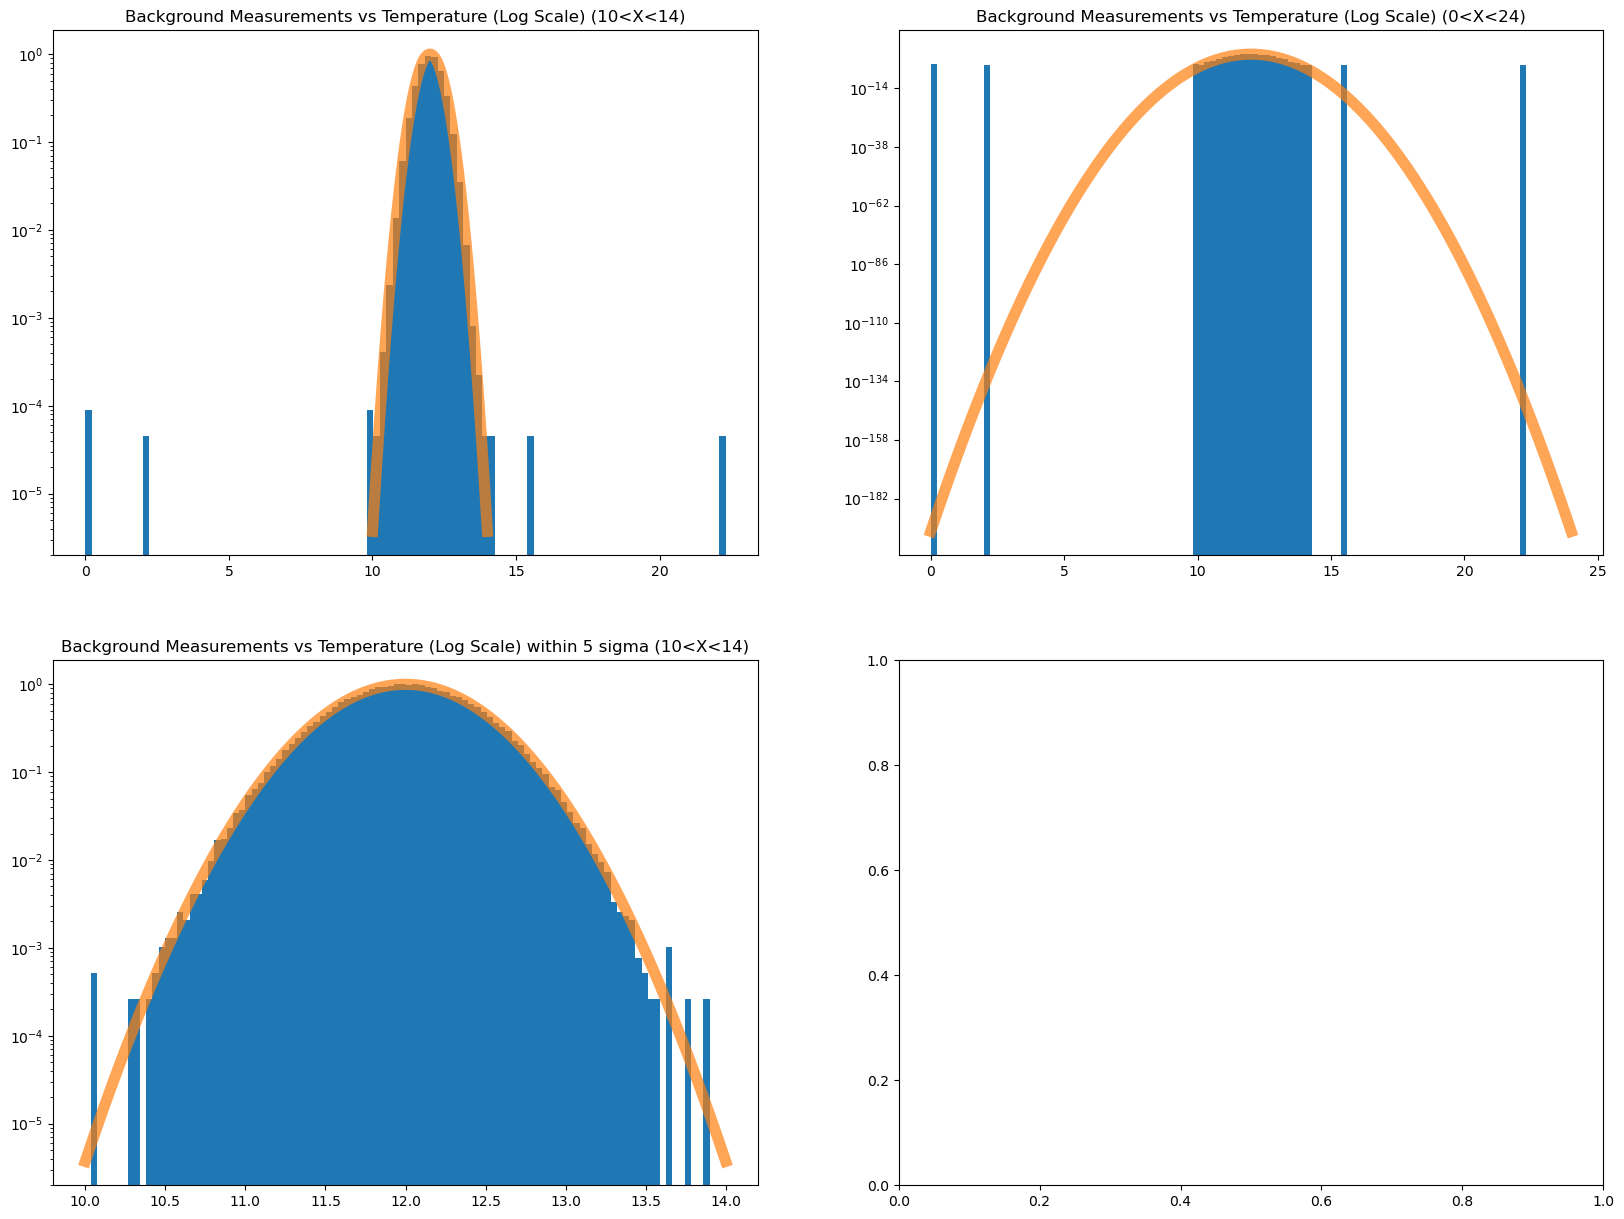

In [3]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplot_mosaic(
    """
    AB
    CD
    """
)

#Plotting the above graph with a Gaussian curve: N(12, 0.4)
ax['A'].hist(d,100, density=True)
ax['A'].set_yscale('log')
x1 = np.linspace(10,14,1000)
ax['A'].plot(x1,stats.norm.pdf(x1,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
ax['A'].set_title("Background Measurements vs Temperature (Log Scale) (10<X<14)")

#Plotting the above graph with a Gaussian curve: N~(12, 0.4). Bigger linspace
ax['B'].hist(d,100, density=True)
ax['B'].set_yscale('log')
x2 = np.linspace(0,24,1000)
ax['B'].plot(x2,stats.norm.pdf(x2,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
ax['B'].set_title("Background Measurements vs Temperature (Log Scale) (0<X<24)")

#Plotting only the points within 5 sigma of the Gaussian curve: N(12, 0.4)
data_good = d[(d < 14) & (d > 10)]
ax['C'].hist(data_good,100, density=True)
ax['C'].set_yscale('log')
x3 = np.linspace(10,14,1000)
ax['C'].plot(x3,stats.norm.pdf(x3,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
ax['C'].set_title("Background Measurements vs Temperature (Log Scale) within 5 sigma (10<X<14)")

plt.show()

#### Part (ii)
State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.

How many values do we measure to be 5$\sigma$ or more away from the expected temperature, 12 Kelvin, given the signal-free background temperature distribution, $T$, follows $T \sim N(12, 0.4)$.

#### Part (iii)
Restate your question in math. Be very clear.

$$n_{bad} = n_{x<10} + n_{x>14}$$

- where $n_{bad}$ is the number of bad measurements
- where $n_{x<10}$ is the number of measurements less than 10 in our data set (5 sigma below the mean)
- where $n_{x>14}$ is the number of measurements greater than 14 in our data set (5 sigma above the mean)

#### Part (iv)
Apply your statistical test and construct a truth table.

In [4]:
print(len(d))
print(len(data_good))

100008
100001


In [5]:
data_TT = {
    " ": ["Test Good", "Test Bad"],
    "Good T": [10000, 0],
    "Bad T": [2, 6]
}

table_TT = pd.DataFrame(data_TT)
table_TT

,,Good T,Bad T
0,Test Good,10000,2
1,Test Bad,0,6


### Part (B)
How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

The number of omissions increases as the statistical threshold decreases. Given your data follows a normal distribution, one can predict the probability of throwing out good data from the probability of getting above/below that value (depending on being above/below the mean).

### Part (C)
Are there mistakes of ommission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

Yes, there is mistakes of inclusion of bad data. They are not necessarily avoidable as "bad data" can be well within a reasonable statistical threshold. In this case, the "bad" value of 12.7 was within 2$\sigma$ of the mean of 12. Typically, the smaller your statistical threshold, the less mistakes of omission you will have. But this can come at the cost of omitted good data.

## Question 2
In this example we will be looking for asteroids. If we look at the alignment of stars on subsequent images, they don't perfectly align due to atmospheric and instrumental effects (even ignoring proper motion). The resulting distribution is two dimensional, and for this lab let's assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if I histogram how far all the (stationary) stars appear to have moved I get something like:

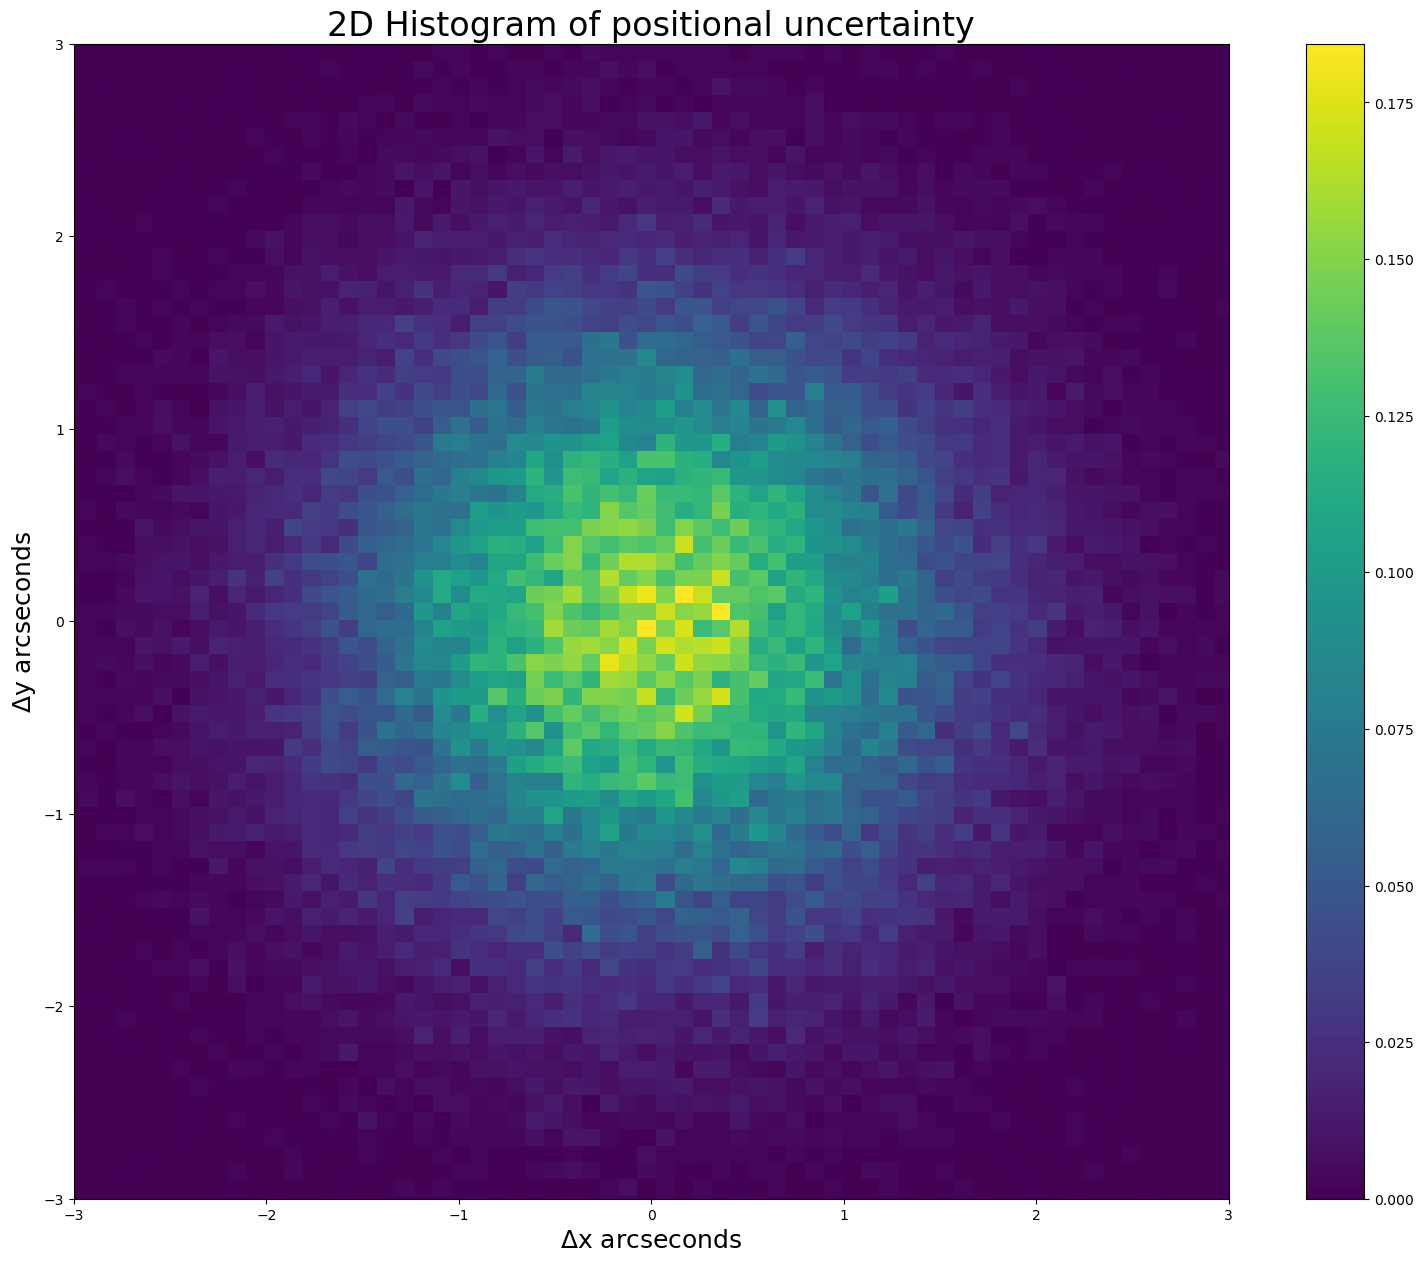

In [6]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)
plt.show()

If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds?

### Part (A)
What is the question in words?

How large is a $5\sigma$ detection of motion in arcseconds given that the distribution follows a 2D Gaussian with $\sigma = 1$.

### Part (B)
What is the question in math? 

The probability that a measurement is not within 5 sigma from a standard normal curve:
$$ P(x < n_{5\sigma}) = \frac{1}{\sqrt{2\pi}}\int_{5}^{\infty}{e^{-\frac{x^2}{2}}}dx$$

The amplitude of a 2D Gaussian follows a Rayleigh distribution:
$$f(x;\sigma )={\frac {x}{\sigma ^{2}}}e^{-x^{2}/(2\sigma ^{2})},\quad x\geq 0$$

So, to find the measurement not within 5$\sigma$ ($n_{5\sigma}$) where $\sigma = 1$:
$$ P(x < n_{5\sigma}) = \int_{n_{5\sigma}}^{\infty}{\frac {x}{\sigma ^{2}}}e^{-x^{2}/(2\sigma ^{2})dx}$$

### Part (C)
What distance in arcseconds represents a 5 sigma detection of motion?

In [7]:
prob_2c = stats.norm.sf(5)
my_dist = stats.rayleigh.isf(prob_2c)

In [8]:
print(f"The distance that represents a 5 sigma detection of motion is {my_dist:.4f} arcseconds.")

The distance that represents a 5 sigma detection of motion is 5.4891 arcseconds.


## Question 3
As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

### Part (A) 
What is the question in words?

For an observation of the moon for 8 hours per night for 15 nights, how significant is the moon blocking cosmic rays to our detection given we observe 6800 cosmic rays and that expected rate is one cosmic ray per minute where detection in given by a Poisson distribution?

### Part (B)
Translate the question to math, describing both the expected background pdf() and the integral you need to do.



Cosmic ray detected follow a Poisson distribution:
$$ P(X=k) = \frac {\lambda ^{k}e^{-\lambda }}{k!}$$

- where $\lambda$ is the expected number of events (1 cosmic ray/minute * 60 minutes/hour * 8 hours/night * 15 nights = 7200 cosmic rays over 15 nights)
- where $k$ is the number of occurences (6800)

So:

$$P(X \leq 6800) = \sum_{k=1}^{6800}\frac{7200^{k}e^{-7200}}{k!}$$

Then convert it into sigma (n):
$$ P(X \leq 6800) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{n}{e^{-\frac{X^2}{2}}}dX$$

### Part (C)
Convert to sigma.

In [9]:
prob3c = stats.poisson.cdf(6800, 7200)
sigma_3c = stats.norm.ppf(prob3c)

In [10]:
print(f"There is a {abs(sigma_3c):.4f} sigma significance to our moon observation.")

There is a 4.7507 sigma significance to our moon observation.
